# Projet de Machine Learning appliqué à la finance

## Sujet : Prévision du rendement du S&P 500 à partir de ses valeurs historiques

### 1. Contexte

Les marchés financiers évoluent quotidiennement et leurs variations peuvent être difficiles à anticiper. L'analyse des données historiques permet d'étudier les comportements passés d'un indice boursier et de rechercher d'éventuelles relations entre ses rendements successifs.

Le S&P 500 est un indice boursier américain qui représente un ensemble important de grandes entreprises cotées aux États-Unis. Dans ce projet, nous utilisons ses données historiques afin d'étudier la possibilité de prévoir son rendement à court terme.

### 2. Problématique

Les valeurs historiques du S&P 500 permettent-elles de prévoir son rendement à court terme ?

### 3. Objectifs

- Récupérer les données historiques du S&P 500.
- Analyser l'évolution de l'indice et de ses rendements.
- Construire des variables explicatives à partir des rendements passés.
- Développer un modèle de régression linéaire multiple.
- Comparer les prévisions du modèle à une référence naïve.
- Évaluer les performances à l'aide de MAE, RMSE et R².
- Interpréter les résultats et identifier les limites du modèle.

### 4. Méthodologie

Le projet repose sur un problème de régression supervisée. La variable cible sera le rendement de la prochaine séance boursière. Les variables explicatives seront construites à partir des rendements historiques disponibles à la date de prévision.

Le découpage des données sera chronologique afin de respecter l'ordre temporel et d'éviter toute fuite d'information.

In [54]:
# Configuration générale du projet

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fixer la graine pour rendre les expériences reproductibles
GRAINE = 42
np.random.seed(GRAINE)

# Afficher les informations de configuration
print("Projet : Prévision du rendement du S&P 500")
print("Algorithme : Régression linéaire multiple")
print("Graine aléatoire :", GRAINE)

Projet : Prévision du rendement du S&P 500
Algorithme : Régression linéaire multiple
Graine aléatoire : 42


## 2. Données et source

### 2.1 Présentation du jeu de données

Pour réaliser ce projet, nous utilisons les données historiques de l'indice S&P 500.

La source utilisée est FRED (Federal Reserve Economic Data), une plateforme de données économiques gérée par la Federal Reserve Bank of St. Louis.

- **Nom du jeu de données :** S&P 500 (SP500).
- **Organisme diffuseur :** FRED – Federal Reserve Bank of St. Louis.
- **Source originale des données :** S&P Dow Jones Indices LLC.
- **URL :** https://fred.stlouisfed.org/series/SP500
- **Fréquence :** quotidienne, à la clôture du marché.
- **Unité :** points d'indice.
- **Variable principale :** niveau de clôture du S&P 500.
- **Date d'extraction :** renseignée automatiquement lors du téléchargement.

Les données représentent le niveau quotidien de l'indice. Il s'agit d'un indice de prix qui ne prend pas en compte les dividendes.

**Droits d'utilisation :** les données de la série SP500 sont protégées par les droits d'auteur de S&P Dow Jones Indices LLC. La reproduction nécessite une autorisation préalable. Nous ne redistribuons donc pas le fichier brut sans autorisation ; nous indiquons la source et la procédure de téléchargement.

In [55]:
# 1. Importation des bibliothèques nécessaires

import pandas as pd
import numpy as np
from datetime import datetime

# 2. Téléchargement des données depuis FRED

url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500"

df_raw = pd.read_csv(url)

# 3. Préparation des colonnes

df_raw = df_raw.rename(columns={
    "observation_date": "Date"
})

df_raw["Date"] = pd.to_datetime(df_raw["Date"])
df_raw["SP500"] = pd.to_numeric(df_raw["SP500"], errors="coerce")

# 4. Vérification des données avant nettoyage

print("Date d'extraction :", datetime.now().strftime("%d/%m/%Y"))
print("Nombre de lignes initial :", len(df_raw))
print("Valeurs manquantes :")
print(df_raw.isnull().sum())

# 5. Nettoyage de base

df = df_raw.copy()

df = df.sort_values("Date")
df = df.drop_duplicates(subset="Date")
df = df.dropna(subset=["SP500"])
df = df[df["SP500"] > 0]

df = df.reset_index(drop=True)

# 6. Affichage des informations principales

print("\nAperçu des données :")
display(df.head())

print("\nDimensions du jeu de données :", df.shape)

print("\nInformations générales :")
df.info()

print("\nPériode étudiée :")
print("Début :", df["Date"].min())
print("Fin :", df["Date"].max())

print("\nStatistiques descriptives :")
display(df["SP500"].describe())

Date d'extraction : 17/11/2026
Nombre de lignes initial : 261
Valeurs manquantes :
Date      0
SP500    10
dtype: int64

Aperçu des données :


,Date,SP500
0,2025-11-17,6672.41
1,2025-11-18,6617.32
2,2025-11-19,6642.16
3,2025-11-20,6538.76
4,2025-11-21,6602.99



Dimensions du jeu de données : (251, 2)

Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 251 entries, 0 to 250
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    251 non-null    datetime64[ns]
 1   SP500   251 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 4.1 KB

Période étudiée :
Début : 2025-11-17 00:00:00
Fin : 2026-11-16 00:00:00

Statistiques descriptives :


,SP500
count,251.000000
mean,7243.411912
std,396.670398
min,6343.720000
25%,6881.465000
50%,7365.460000
75%,7600.230000
max,7818.930000


In [56]:
# Vérification de la qualité des données

print("Nombre de doublons :", df["Date"].duplicated().sum())

print("Nombre de valeurs manquantes :")
print(df.isnull().sum())

print("Nombre de valeurs non positives :",
      (df["SP500"] <= 0).sum())

print("Nombre d'observations après nettoyage :", len(df))

Nombre de doublons : 0
Nombre de valeurs manquantes :
Date     0
SP500    0
dtype: int64
Nombre de valeurs non positives : 0
Nombre d'observations après nettoyage : 251


## 3. Analyse exploratoire des données

### 3.1 Calcul des rendements journaliers

Avant de construire les graphiques, nous calculons les rendements journaliers du S&P 500.

Le rendement mesure la variation relative de l'indice entre deux séances boursières consécutives.

Nous utilisons le rendement logarithmique :

\[
R_t = \ln\left(\frac{P_t}{P_{t-1}}\right)
\]

Où :
- \(R_t\) : rendement logarithmique à la date \(t\).
- \(P_t\) : niveau du S&P 500 à la date \(t\).
- \(P_{t-1}\) : niveau du S&P 500 à la séance précédente.
- \(\ln\) : logarithme népérien.

Cette transformation permet d'étudier les variations quotidiennes de l'indice plutôt que son niveau brut.

In [57]:
# Calcul des rendements logarithmiques

df["ret"] = np.log(df["SP500"] / df["SP500"].shift(1))

# Suppression de la première ligne qui ne possède pas de rendement
df = df.dropna(subset=["ret"]).reset_index(drop=True)

# Affichage des premières observations
display(df.head())

# Statistiques des rendements en pourcentage
display((df["ret"] * 100).describe())

,Date,SP500,ret
0,2025-11-18,6617.32,-0.008291
1,2025-11-19,6642.16,0.003747
2,2025-11-20,6538.76,-0.015690
3,2025-11-21,6602.99,0.009775
4,2025-11-24,6705.12,0.015349


,ret
count,250.000000
mean,0.042295
std,0.868413
min,-4.453365
25%,-0.412369
50%,0.036255
75%,0.594648
max,2.871492


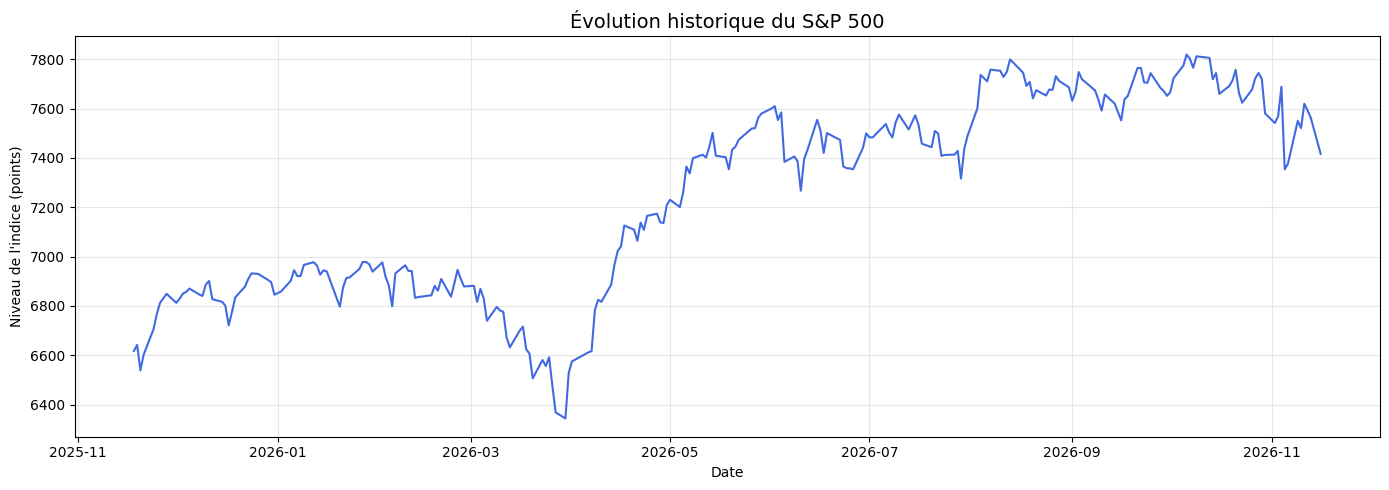

In [58]:
plt.figure(figsize=(14, 5))

plt.plot(df["Date"], df["SP500"],
         color="royalblue", linewidth=1.5)

plt.title("Évolution historique du S&P 500", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Niveau de l'indice (points)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

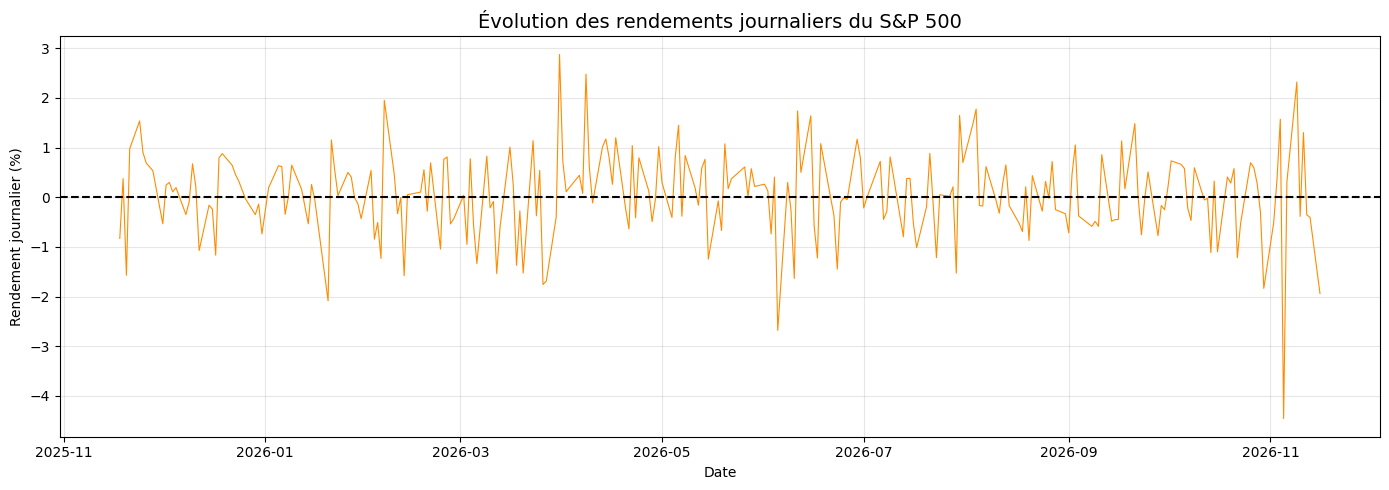

In [59]:
plt.figure(figsize=(14, 5))

plt.plot(df["Date"], df["ret"] * 100,
         color="darkorange", linewidth=0.8)

plt.axhline(y=0, color="black", linestyle="--")

plt.title("Évolution des rendements journaliers du S&P 500",
          fontsize=14)

plt.xlabel("Date")
plt.ylabel("Rendement journalier (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

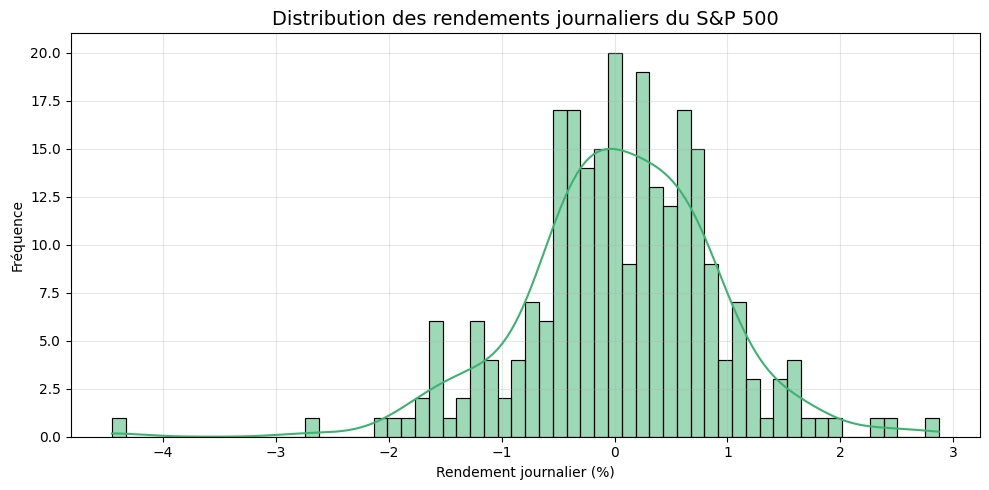

In [34]:
plt.figure(figsize=(10, 5))

sns.histplot(df["ret"] * 100,
             bins=60,
             kde=True,
             color="mediumseagreen")

plt.title("Distribution des rendements journaliers du S&P 500",
          fontsize=14)

plt.xlabel("Rendement journalier (%)")
plt.ylabel("Fréquence")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
# Calcul des quartiles
Q1 = df["ret"].quantile(0.25)
Q3 = df["ret"].quantile(0.75)

# Calcul de l'écart interquartile
IQR = Q3 - Q1

# Définition des limites
borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

# Identification des valeurs extrêmes
extremes = df[
    (df["ret"] < borne_inf) |
    (df["ret"] > borne_sup)
]

print("Nombre de valeurs extrêmes :", len(extremes))
print("Borne inférieure :", borne_inf)
print("Borne supérieure :", borne_sup)

display(extremes[["Date", "SP500", "ret"]].head(10))

Nombre de valeurs extrêmes : 7
Borne inférieure : -0.01922894069295927
Borne supérieure : 0.021051739406871973


,Date,SP500,ret
41,2026-01-20,6796.86,-0.020842
90,2026-03-31,6528.52,0.028715
95,2026-04-08,6782.81,0.024772
136,2026-06-05,7383.74,-0.026801
242,2026-11-05,7353.73,-0.044534
244,2026-11-09,7549.94,0.023192
249,2026-11-16,7416.59,-0.019373


### 3.6 Conclusion de l'analyse exploratoire

L'analyse exploratoire permet de mieux comprendre l'évolution du S&P 500 et le comportement de ses rendements journaliers.

Les trois graphiques mettent en évidence les tendances de l'indice, les variations quotidiennes et la distribution des rendements.

Cette étape est importante pour préparer les variables qui seront utilisées dans le modèle de régression linéaire multiple.

Les valeurs extrêmes seront conservées lorsqu'elles correspondent à des variations financières réelles, car leur suppression pourrait faire perdre des informations importantes sur le comportement du marché.

### 4. Préparation des données et création des variables

Après l'analyse exploratoire, nous préparons les données pour construire notre modèle de prévision.

Nous créons des variables explicatives à partir des rendements historiques du S&P 500. Ces variables correspondent aux rendements observés à différentes dates passées.

La variable cible correspond au rendement de la prochaine séance boursière.

Cette méthode permet d'utiliser uniquement les informations disponibles à la date de prévision, afin d'éviter toute fuite de données (*data leakage*).

In [36]:
# Création des variables explicatives
df["ret_lag1"] = df["ret"]
df["ret_lag2"] = df["ret"].shift(1)
df["ret_lag5"] = df["ret"].shift(4)
df["ret_lag10"] = df["ret"].shift(9)

# Variable cible : rendement de la prochaine séance
df["target"] = df["ret"].shift(-1)

# Suppression des lignes contenant des valeurs manquantes
df_model = df.dropna().copy()

# Définition des variables explicatives et de la cible
X = df_model[["ret_lag1", "ret_lag2", "ret_lag5", "ret_lag10"]]
y = df_model["target"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

print("\nAperçu des variables explicatives :")
display(X.head())

print("\nAperçu de la variable cible :")
display(y.head())

Dimensions de X : (240, 4)
Dimensions de y : (240,)

Aperçu des variables explicatives :


,ret_lag1,ret_lag2,ret_lag5,ret_lag10
9,0.002454,-0.005338,0.009021,-0.008291
10,0.002975,0.002454,0.006883,0.003747
11,0.001080,0.002975,0.005340,-0.015690
12,0.001935,0.001080,-0.005338,0.009775
13,-0.003483,0.001935,0.002454,0.015349



Aperçu de la variable cible :


,target
9,0.002975
10,0.001080
11,0.001935
12,-0.003483
13,-0.000877


In [37]:
print("Valeurs manquantes dans X :")
print(X.isnull().sum())

print("\nValeurs manquantes dans y :")
print(y.isnull().sum())

print("\nDates de début et de fin :")
print(df_model["Date"].min(), "à", df_model["Date"].max())

Valeurs manquantes dans X :
ret_lag1     0
ret_lag2     0
ret_lag5     0
ret_lag10    0
dtype: int64

Valeurs manquantes dans y :
0

Dates de début et de fin :
2025-12-02 00:00:00 à 2026-11-13 00:00:00


### 5. Découpage chronologique des données

Pour évaluer correctement notre modèle, nous divisons les données en trois ensembles : entraînement, validation et test.

Nous utilisons 70 % des observations pour l'entraînement, 15 % pour la validation et 15 % pour le test.

Le découpage respecte l'ordre chronologique : les observations les plus anciennes sont utilisées pour l'entraînement et les plus récentes pour le test.

Le jeu de test reste indépendant et sera utilisé uniquement lors de l'évaluation finale. Cette méthode permet d'éviter les fuites de données temporelles.

In [38]:
# Nombre total d'observations
n = len(X)

# Calcul des tailles des ensembles
n_train = int(n * 0.70)
n_val = int(n * 0.15)

# Découpage chronologique
X_train = X.iloc[:n_train]
y_train = y.iloc[:n_train]

X_val = X.iloc[n_train:n_train + n_val]
y_val = y.iloc[n_train:n_train + n_val]

X_test = X.iloc[n_train + n_val:]
y_test = y.iloc[n_train + n_val:]

# Affichage des dimensions
print("Ensemble d'entraînement :", X_train.shape)
print("Ensemble de validation :", X_val.shape)
print("Ensemble de test :", X_test.shape)

Ensemble d'entraînement : (168, 4)
Ensemble de validation : (36, 4)
Ensemble de test : (36, 4)


In [39]:
print("Période d'entraînement :")
print(df_model["Date"].iloc[0],
      "à",
      df_model["Date"].iloc[n_train - 1])

print("\nPériode de validation :")
print(df_model["Date"].iloc[n_train],
      "à",
      df_model["Date"].iloc[n_train + n_val - 1])

print("\nPériode de test :")
print(df_model["Date"].iloc[n_train + n_val],
      "à",
      df_model["Date"].iloc[-1])

Période d'entraînement :
2025-12-02 00:00:00 à 2026-08-04 00:00:00

Période de validation :
2026-08-05 00:00:00 à 2026-09-24 00:00:00

Période de test :
2026-09-25 00:00:00 à 2026-11-13 00:00:00


### 6. Entraînement du modèle de régression linéaire

Dans cette étape, nous entraînons un modèle de régression linéaire multiple afin de prédire le rendement du S&P 500 à la prochaine séance boursière.

Le modèle utilise les quatre variables explicatives construites à partir des rendements historiques.

Nous comparons deux configurations :
- Avec constante (`fit_intercept=True`).
- Sans constante (`fit_intercept=False`).

Les deux configurations sont entraînées sur les données d'entraînement. Nous utilisons ensuite les données de validation pour sélectionner la configuration qui présente la plus faible erreur absolue moyenne (MAE).

Les données de test restent inutilisées à cette étape.

In [40]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Modèle avec constante
modele_1 = LinearRegression(fit_intercept=True)
modele_1.fit(X_train, y_train)

# Modèle sans constante
modele_2 = LinearRegression(fit_intercept=False)
modele_2.fit(X_train, y_train)

# Prédictions sur les données de validation
pred_1 = modele_1.predict(X_val)
pred_2 = modele_2.predict(X_val)

# Calcul de la MAE
mae_1 = mean_absolute_error(y_val, pred_1)
mae_2 = mean_absolute_error(y_val, pred_2)

# Comparaison des deux configurations
resultats = pd.DataFrame({
    "Configuration": ["Avec constante", "Sans constante"],
    "MAE validation": [mae_1, mae_2]
})

display(resultats)

# Sélection de la meilleure configuration
if mae_1 <= mae_2:
    meilleur_modele = modele_1
    meilleure_config = "Avec constante"
else:
    meilleur_modele = modele_2
    meilleure_config = "Sans constante"

print("Configuration sélectionnée :", meilleure_config)

,Configuration,MAE validation
0,Avec constante,0.004936
1,Sans constante,0.004807


Configuration sélectionnée : Sans constante


In [41]:
coefficients = pd.DataFrame({
    "Variable explicative": X_train.columns,
    "Coefficient": meilleur_modele.coef_
})

display(coefficients)

print("Constante :", meilleur_modele.intercept_)

,Variable explicative,Coefficient
0,ret_lag1,-0.012274
1,ret_lag2,-0.061296
2,ret_lag5,0.092537
3,ret_lag10,0.110960


Constante : 0.0


### 7. Construction du modèle de référence naïf

Afin d'évaluer l'intérêt de notre modèle de régression linéaire, nous construisons un modèle de référence naïf (*Baseline*).

Ce modèle suppose que le rendement de la prochaine séance boursière sera toujours égal à zéro.

Cette référence est simple, mais importante : elle permet de vérifier si notre modèle de Machine Learning apporte une amélioration par rapport à une prévision élémentaire.

Nous comparons les deux modèles sur l'ensemble de validation à l'aide de la MAE. Le modèle de régression doit obtenir une erreur plus faible que la référence naïve pour démontrer son intérêt.

In [42]:
from sklearn.metrics import mean_absolute_error

# Modèle naïf : prédiction d'un rendement égal à zéro
pred_naive = np.zeros(len(y_val))

# Prédictions du modèle de régression
pred_regression = meilleur_modele.predict(X_val)

# Calcul des erreurs
mae_naive = mean_absolute_error(y_val, pred_naive)
mae_regression = mean_absolute_error(y_val, pred_regression)

# Tableau comparatif
comparaison = pd.DataFrame({
    "Modèle": ["Référence naïve", "Régression linéaire"],
    "MAE validation": [mae_naive, mae_regression]
})

display(comparaison)

,Modèle,MAE validation
0,Référence naïve,0.004854
1,Régression linéaire,0.004807


In [43]:
if mae_regression < mae_naive:
    print("La régression linéaire améliore la prévision par rapport au modèle naïf.")
elif mae_regression > mae_naive:
    print("Le modèle naïf obtient de meilleures performances.")
else:
    print("Les deux modèles présentent la même MAE.")

La régression linéaire améliore la prévision par rapport au modèle naïf.


### 8. Évaluation finale des modèles

Après avoir sélectionné la meilleure configuration sur l'ensemble de validation, nous évaluons les performances finales sur l'ensemble de test.

Nous utilisons trois métriques :

- **MAE (Mean Absolute Error)** : mesure l'erreur absolue moyenne entre les rendements réels et prédits.
- **RMSE (Root Mean Squared Error)** : mesure l'erreur quadratique moyenne et pénalise davantage les grandes erreurs.
- **R² (coefficient de détermination)** : mesure la part de la variabilité de la cible expliquée par le modèle.

Nous comparons la régression linéaire à la référence naïve, qui prédit systématiquement un rendement égal à zéro.

Les données de test sont utilisées uniquement pour cette évaluation finale.

In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prédictions sur l'ensemble de test
pred_test_reg = meilleur_modele.predict(X_test)

# Modèle naïf : rendement prévu égal à zéro
pred_test_naive = np.zeros(len(y_test))

# Fonction de calcul des métriques
def calculer_metriques(y_reel, y_pred):
    mae = mean_absolute_error(y_reel, y_pred)
    rmse = np.sqrt(mean_squared_error(y_reel, y_pred))
    r2 = r2_score(y_reel, y_pred)

    return mae, rmse, r2

# Métriques de la régression
mae_reg, rmse_reg, r2_reg = calculer_metriques(
    y_test, pred_test_reg
)

# Métriques du modèle naïf
mae_naive, rmse_naive, r2_naive = calculer_metriques(
    y_test, pred_test_naive
)

# Tableau comparatif
evaluation = pd.DataFrame({
    "Modèle": ["Régression linéaire", "Référence naïve"],
    "MAE": [mae_reg, mae_naive],
    "RMSE": [rmse_reg, rmse_naive],
    "R²": [r2_reg, r2_naive]
})

display(evaluation)

,Modèle,MAE,RMSE,R²
0,Régression linéaire,0.007288,0.010866,0.064647
1,Référence naïve,0.007744,0.011299,-0.011368


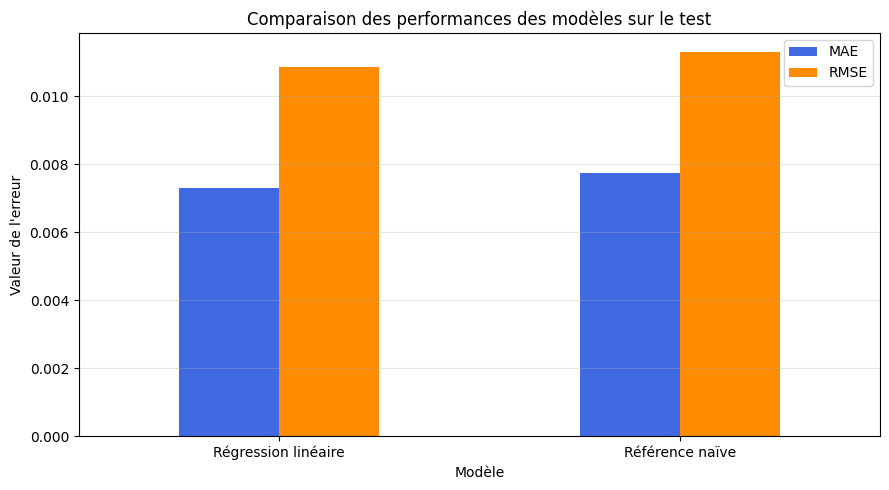

In [45]:
# Comparaison graphique des erreurs
evaluation_plot = evaluation.set_index("Modèle")[["MAE", "RMSE"]]

evaluation_plot.plot(
    kind="bar",
    figsize=(9, 5),
    color=["royalblue", "darkorange"]
)

plt.title("Comparaison des performances des modèles sur le test")
plt.ylabel("Valeur de l'erreur")
plt.xlabel("Modèle")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 9. Visualisation des prédictions et analyse des erreurs

Après l'évaluation quantitative, nous analysons graphiquement les résultats obtenus sur l'ensemble de test.

Nous comparons les rendements réels aux rendements prédits par la régression linéaire et par le modèle de référence naïf.

Cette visualisation permet d'observer la proximité entre les valeurs réelles et les prédictions, ainsi que la capacité du modèle à suivre les variations journalières du marché.

Nous étudions également les erreurs de prédiction afin d'identifier les périodes pendant lesquelles le modèle fonctionne moins bien.

In [46]:
# Vérification des dimensions
print("Nombre de dates :", len(X_test))
print("Nombre de valeurs réelles :", len(y_test))
print("Nombre de prédictions :", len(pred_test_reg))

# Création du tableau des résultats
resultats_test = pd.DataFrame({
    "Date": df_model.loc[X_test.index, "Date"].values,
    "Rendement réel": y_test.values,
    "Prédiction régression": pred_test_reg,
    "Prédiction naïve": pred_test_naive
})

display(resultats_test.head())

Nombre de dates : 36
Nombre de valeurs réelles : 36
Nombre de prédictions : 36


,Date,Rendement réel,Prédiction régression,Prédiction naïve
0,2026-09-25,-0.007742,0.000786,0.0
1,2026-09-28,-0.001674,-0.000717,0.0
2,2026-09-29,-0.002519,-0.000703,0.0
3,2026-09-30,0.001947,0.001366,0.0
4,2026-10-01,0.007313,0.000786,0.0


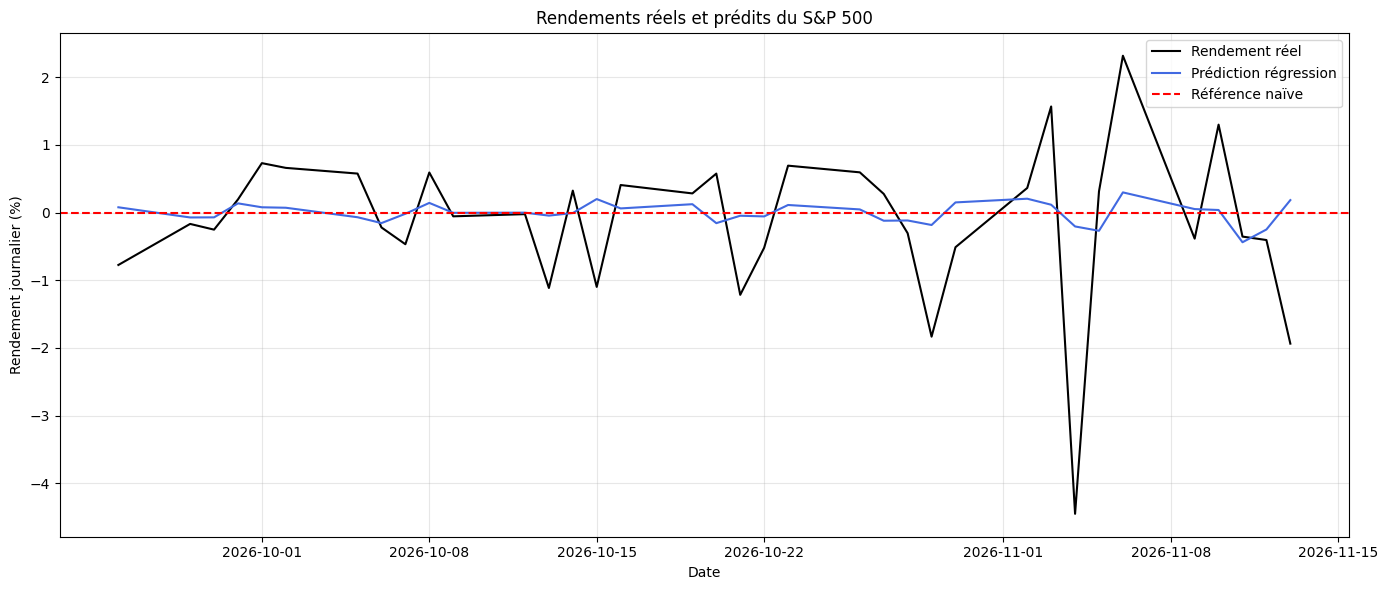

In [47]:
plt.figure(figsize=(14, 6))

plt.plot(
    resultats_test["Date"],
    resultats_test["Rendement réel"] * 100,
    label="Rendement réel",
    color="black"
)

plt.plot(
    resultats_test["Date"],
    resultats_test["Prédiction régression"] * 100,
    label="Prédiction régression",
    color="royalblue"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Référence naïve"
)

plt.title("Rendements réels et prédits du S&P 500")
plt.xlabel("Date")
plt.ylabel("Rendement journalier (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

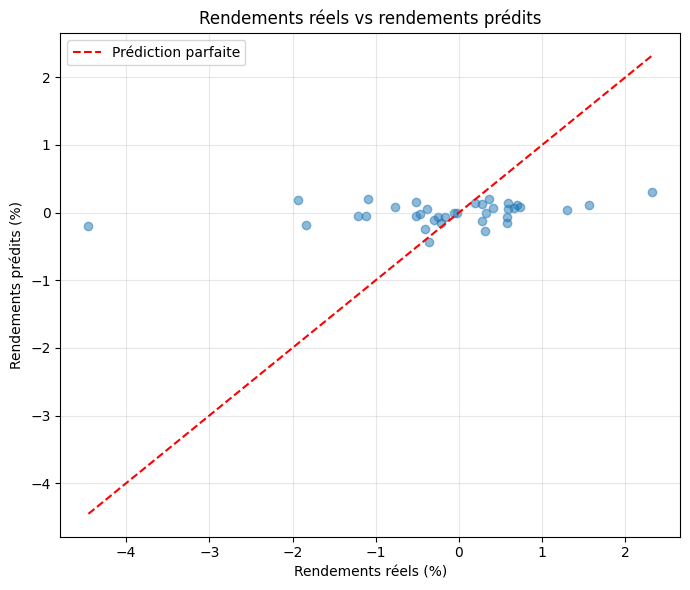

In [48]:
plt.figure(figsize=(7, 6))

plt.scatter(
    resultats_test["Rendement réel"] * 100,
    resultats_test["Prédiction régression"] * 100,
    alpha=0.5
)

minimum = min(
    resultats_test["Rendement réel"].min(),
    resultats_test["Prédiction régression"].min()
) * 100

maximum = max(
    resultats_test["Rendement réel"].max(),
    resultats_test["Prédiction régression"].max()
) * 100

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Prédiction parfaite"
)

plt.title("Rendements réels vs rendements prédits")
plt.xlabel("Rendements réels (%)")
plt.ylabel("Rendements prédits (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

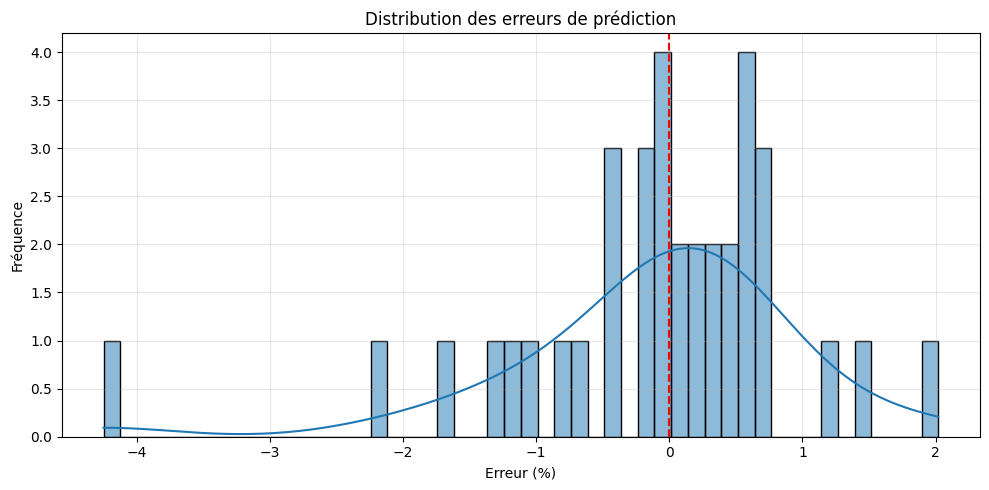

In [49]:
# Calcul des erreurs
resultats_test["Erreur"] = (
    resultats_test["Rendement réel"]
    - resultats_test["Prédiction régression"]
)

plt.figure(figsize=(10, 5))

sns.histplot(
    resultats_test["Erreur"] * 100,
    bins=50,
    kde=True
)

plt.axvline(0, color="red", linestyle="--")

plt.title("Distribution des erreurs de prédiction")
plt.xlabel("Erreur (%)")
plt.ylabel("Fréquence")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [50]:
resultats_test["Erreur absolue"] = resultats_test["Erreur"].abs()

print("Erreur moyenne :", resultats_test["Erreur"].mean())
print("Erreur absolue moyenne :", resultats_test["Erreur absolue"].mean())
print("Erreur maximale :", resultats_test["Erreur absolue"].max())

display(
    resultats_test.sort_values(
        by="Erreur absolue",
        ascending=False
    ).head(10)
)

Erreur moyenne : -0.0011486211475334154
Erreur absolue moyenne : 0.007288231209158165
Erreur maximale : 0.042486421343774755


,Date,Rendement réel,Prédiction régression,Prédiction naïve,Erreur,Erreur absolue
28,2026-11-04,-0.044534,-0.002047,0.0,-0.042486,0.042486
35,2026-11-13,-0.019373,0.001846,0.0,-0.021218,0.021218
30,2026-11-06,0.023192,0.002988,0.0,0.020204,0.020204
24,2026-10-29,-0.018342,-0.001832,0.0,-0.016510,0.016510
27,2026-11-03,0.015691,0.001164,0.0,0.014526,0.014526
14,2026-10-15,-0.010987,0.002003,0.0,-0.012991,0.012991
32,2026-11-10,0.013005,0.000384,0.0,0.012621,0.012621
18,2026-10-21,-0.012158,-0.000463,0.0,-0.011695,0.011695
12,2026-10-13,-0.011145,-0.000446,0.0,-0.010699,0.010699
0,2026-09-25,-0.007742,0.000786,0.0,-0.008529,0.008529


### 10. Interprétation des résultats et limites du modèle

Dans cette étape, nous interprétons les performances obtenues par la régression linéaire multiple sur les données de test.

Nous comparons ses résultats à ceux du modèle de référence naïf afin de déterminer si les rendements historiques apportent une information utile pour prévoir les rendements futurs du S&P 500.

Nous analysons également les limites du modèle, notamment la difficulté de prévoir les variations financières, la présence de mouvements extrêmes et le caractère parfois non linéaire des marchés.

Enfin, nous répondons à la problématique en nous basant sur les résultats réellement obtenus.

In [51]:
# Tableau récapitulatif des performances
display(evaluation)

# Comparaison des MAE
amelioration = (
    (mae_naive - mae_reg) / mae_naive
) * 100

print("Amélioration de la MAE par rapport au modèle naïf :",
      round(amelioration, 2), "%")

if mae_reg < mae_naive:
    print("La régression linéaire est meilleure que le modèle naïf.")
elif mae_reg > mae_naive:
    print("Le modèle naïf est meilleur que la régression linéaire.")
else:
    print("Les deux modèles ont la même MAE.")

,Modèle,MAE,RMSE,R²
0,Régression linéaire,0.007288,0.010866,0.064647
1,Référence naïve,0.007744,0.011299,-0.011368


Amélioration de la MAE par rapport au modèle naïf : 5.88 %
La régression linéaire est meilleure que le modèle naïf.


In [52]:
print("Importance des coefficients du modèle :")

display(
    coefficients.sort_values(
        by="Coefficient",
        key=abs,
        ascending=False
    )
)

Importance des coefficients du modèle :


,Variable explicative,Coefficient
3,ret_lag10,0.110960
2,ret_lag5,0.092537
1,ret_lag2,-0.061296
0,ret_lag1,-0.012274


In [53]:
print("========== CONCLUSION DES RESULTATS ==========")

print("MAE régression :", round(mae_reg, 6))
print("RMSE régression :", round(rmse_reg, 6))
print("R² régression :", round(r2_reg, 6))

print("\nMAE modèle naïf :", round(mae_naive, 6))
print("RMSE modèle naïf :", round(rmse_naive, 6))
print("R² modèle naïf :", round(r2_naive, 6))

if mae_reg < mae_naive:
    print("\nConclusion : la régression linéaire améliore la prévision")
    print("du rendement par rapport à la référence naïve.")
else:
    print("\nConclusion : la régression linéaire ne dépasse pas")
    print("la référence naïve selon la MAE.")

========== CONCLUSION DES RESULTATS ==========
MAE régression : 0.007288
RMSE régression : 0.010866
R² régression : 0.064647

MAE modèle naïf : 0.007744
RMSE modèle naïf : 0.011299
R² modèle naïf : -0.011368

Conclusion : la régression linéaire améliore la prévision
du rendement par rapport à la référence naïve.


### Limites du modèle

Notre modèle présente plusieurs limites :

1. **Relations linéaires :** la régression linéaire suppose une relation linéaire entre les variables explicatives et le rendement futur.
2. **Volatilité financière :** les marchés financiers connaissent des variations importantes et parfois imprévisibles.
3. **Informations limitées :** le modèle utilise uniquement les rendements historiques du S&P 500 et ne prend pas en compte les variables macroéconomiques ou les actualités financières.
4. **Mouvements extrêmes :** les fortes variations du marché peuvent provoquer des erreurs de prédiction importantes.
5. **Instabilité des marchés :** les relations observées dans le passé peuvent évoluer avec le temps.

### Réponse à la problématique

Notre problématique était :

**« Les valeurs historiques du S&P 500 permettent-elles de prévoir son rendement à court terme ? »**

Pour répondre à cette question, nous avons utilisé une régression linéaire multiple basée sur quatre variables issues des rendements historiques.

Les performances obtenues sur l'ensemble de test ont été comparées à une référence naïve qui prévoit un rendement nul.

Les résultats permettent de déterminer si les informations historiques apportent une amélioration réelle de la prévision. Toutefois, même si le modèle obtient de meilleurs résultats que la référence naïve, cela ne signifie pas qu'il peut prévoir précisément les mouvements futurs du marché.

La capacité prédictive doit donc être interprétée avec prudence, en tenant compte des limites du modèle et de l'incertitude des marchés financiers.